# FL-PERF-002.3 — Benchmark with 50 virtual clients

*Epic EPIC-001 · story fl_perf_002 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Measure overhead at 50 clients.

## 2. Scientific background
Performance of privacy-preserving FL is dominated by cryptographic computation and ciphertext/mask expansion [kairouz2021, li2020challenges]. All clients here are virtual and share one machine, so wall time includes serial execution of clients.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** What are the training-time, communication, memory and CPU overheads of each secure aggregation mechanism?
- **RQ2.** Are the story KPIs (<30% training overhead, <40% communication overhead, <1 pp accuracy loss) met?

## 4. Hypotheses
- **H1.** Secure aggregation overhead exceeds the 30%/40% KPIs for at least some mechanisms in simulation.

## 5. Mathematical formulation
overhead% = 100(x_secure − x_plain)/x_plain; throughput = samples processed / client compute seconds; scaling exponent b from log-log fit time ∝ n^b.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_perf_002"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_perf_002


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`monitoring.py`, `fl.py`, `crypto/*`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
from federated_learning.monitoring.resources import ResourceMonitor
parts = partition_iid(data.y_train, 5, SEED)
with ResourceMonitor(0.02) as m:
    r = run_fl(FLConfig(rounds=3, local_epochs=1, seed=SEED), data, parts)
s = m.summary(); print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in s.items()})
assert s["cpu_time_s"] > 0 and s["wall_s"] > 0

{'wall_s': 0.141, 'cpu_time_s': 0.13, 'cpu_util_mean_pct': 95.683, 'cpu_util_peak_pct': 98.8, 'rss_mean_mb': 740.442, 'rss_peak_mb': 742.035, 'n_samples': 6, 'sample_interval_s': 0.02, 'gpu_available': False, 'gpu_util_pct': None, 'gpu_mem_mb': None}


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-PERF-002.3` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('fl_perf_002.3_runs.csv')

,config,n_clients,seed,rounds,status,acc,f1,train_wall_s,client_time_s,agg_time_s,mean_round_s,up_mb,down_mb,comm_mb_per_round,throughput_samples_per_s,cpu_time_s,cpu_util_mean_pct,cpu_util_peak_pct,rss_mean_mb,rss_peak_mb,gpu_available,max_client_round_s,mlflow_run_id,train_overhead_pct,comm_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain,50,0,10,ok,0.6700,0.4310,1.8743,1.8546,0.0046,0.1874,2.6283,2.6283,0.5257,45293.7307,1.87,99.5306,118.7,998.3128,998.3164,False,0.0099,a8ca57bbe2154fe289e92f15e7a678c8,NaN,NaN,NaN,NaN
1,plain,50,1,10,ok,0.6992,0.4593,1.5526,1.5362,0.0040,0.1553,2.6283,2.6283,0.5257,54680.2194,1.54,99.3000,117.9,998.3279,998.3281,False,0.0068,ba93a6c13b43486e8d09914e54a835db,NaN,NaN,NaN,NaN
2,plain,50,2,10,ok,0.6722,0.4272,1.5153,1.4998,0.0037,0.1515,2.6283,2.6283,0.5257,56005.6534,1.51,98.6103,118.4,998.3318,998.3320,False,0.0051,5036ccddc9bc461ea9ff60d2e225a037,NaN,NaN,NaN,NaN
3,secagg_complete,50,0,10,ok,0.6700,0.4310,8.9603,1.5922,7.3549,0.8960,10.8376,8.0490,1.8887,52757.5306,8.92,99.9387,138.7,999.1246,999.1719,False,0.0103,24a11844fe1f41d49f4d9bd952c7e0ff,378.0683,259.2888,312.3367,0.0
4,secagg_complete,50,1,10,ok,0.6992,0.4593,9.9415,1.9109,8.0127,0.9942,10.8376,8.0490,1.8887,43958.2758,9.88,99.6974,140.4,999.1974,999.2031,False,0.0095,e1eafd8b15cf46e3bf5a59066c731efe,540.3321,259.2888,312.3367,0.0
5,secagg_complete,50,2,10,ok,0.6722,0.4272,10.6484,1.9769,8.6536,1.0648,10.8376,8.0490,1.8887,42490.6791,10.66,100.5605,138.5,999.2409,999.2461,False,0.0069,d9f11e5c913e45c4b9c4d9bdf1769fdb,602.7404,259.2888,312.3367,0.0
6,he_ckks,50,0,10,ok,0.6700,0.4310,7.7607,1.8317,5.9126,0.7761,158.0031,2.6283,16.0631,45858.0714,7.69,100.4409,152.8,1004.4460,1004.9648,False,0.0067,96726fd8f1d94689879dcca5b2ca3057,314.0684,2955.7738,5911.5475,0.0
7,he_ckks,50,1,10,ok,0.6992,0.4593,7.1131,1.8103,5.2888,0.7113,158.1052,2.6283,16.0734,46402.4043,7.04,99.6459,138.6,1004.9648,1004.9648,False,0.0070,206c875d9b5c43eca4f214233b6527ad,358.1539,2957.7159,5915.4318,0.0
8,he_ckks,50,2,10,ok,0.6722,0.4272,7.7603,1.7811,5.9613,0.7760,158.0913,2.6283,16.0720,47162.7872,7.71,100.6648,173.9,1004.9683,1004.9688,False,0.0072,dd15a54d12a44e218ffd44422753b4a3,412.1373,2957.4510,5914.9020,0.0
9,smpc_3party,50,0,10,ok,0.6700,0.4310,9.6834,1.7752,7.8961,0.9683,15.7700,2.6283,1.8398,47319.7588,9.60,99.2790,118.7,1006.7321,1006.9141,False,0.0068,11deea3ec3314ec0953b3dace6a3882b,416.6514,250.0000,500.0000,0.0


## 12. Metrics collection
Metric definitions: Defined in `monitoring.py` docstring and docs/fl_perf_002/metrics_definitions.md: cpu_time_s (cumulative), cpu util mean/peak, RSS mean/peak, logical comm bytes, GPU = unavailable (never estimated).

In [8]:
show_csv('fl_perf_002.3_runs.csv')

,config,n_clients,seed,rounds,status,acc,f1,train_wall_s,client_time_s,agg_time_s,mean_round_s,up_mb,down_mb,comm_mb_per_round,throughput_samples_per_s,cpu_time_s,cpu_util_mean_pct,cpu_util_peak_pct,rss_mean_mb,rss_peak_mb,gpu_available,max_client_round_s,mlflow_run_id,train_overhead_pct,comm_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain,50,0,10,ok,0.6700,0.4310,1.8743,1.8546,0.0046,0.1874,2.6283,2.6283,0.5257,45293.7307,1.87,99.5306,118.7,998.3128,998.3164,False,0.0099,a8ca57bbe2154fe289e92f15e7a678c8,NaN,NaN,NaN,NaN
1,plain,50,1,10,ok,0.6992,0.4593,1.5526,1.5362,0.0040,0.1553,2.6283,2.6283,0.5257,54680.2194,1.54,99.3000,117.9,998.3279,998.3281,False,0.0068,ba93a6c13b43486e8d09914e54a835db,NaN,NaN,NaN,NaN
2,plain,50,2,10,ok,0.6722,0.4272,1.5153,1.4998,0.0037,0.1515,2.6283,2.6283,0.5257,56005.6534,1.51,98.6103,118.4,998.3318,998.3320,False,0.0051,5036ccddc9bc461ea9ff60d2e225a037,NaN,NaN,NaN,NaN
3,secagg_complete,50,0,10,ok,0.6700,0.4310,8.9603,1.5922,7.3549,0.8960,10.8376,8.0490,1.8887,52757.5306,8.92,99.9387,138.7,999.1246,999.1719,False,0.0103,24a11844fe1f41d49f4d9bd952c7e0ff,378.0683,259.2888,312.3367,0.0
4,secagg_complete,50,1,10,ok,0.6992,0.4593,9.9415,1.9109,8.0127,0.9942,10.8376,8.0490,1.8887,43958.2758,9.88,99.6974,140.4,999.1974,999.2031,False,0.0095,e1eafd8b15cf46e3bf5a59066c731efe,540.3321,259.2888,312.3367,0.0
5,secagg_complete,50,2,10,ok,0.6722,0.4272,10.6484,1.9769,8.6536,1.0648,10.8376,8.0490,1.8887,42490.6791,10.66,100.5605,138.5,999.2409,999.2461,False,0.0069,d9f11e5c913e45c4b9c4d9bdf1769fdb,602.7404,259.2888,312.3367,0.0
6,he_ckks,50,0,10,ok,0.6700,0.4310,7.7607,1.8317,5.9126,0.7761,158.0031,2.6283,16.0631,45858.0714,7.69,100.4409,152.8,1004.4460,1004.9648,False,0.0067,96726fd8f1d94689879dcca5b2ca3057,314.0684,2955.7738,5911.5475,0.0
7,he_ckks,50,1,10,ok,0.6992,0.4593,7.1131,1.8103,5.2888,0.7113,158.1052,2.6283,16.0734,46402.4043,7.04,99.6459,138.6,1004.9648,1004.9648,False,0.0070,206c875d9b5c43eca4f214233b6527ad,358.1539,2957.7159,5915.4318,0.0
8,he_ckks,50,2,10,ok,0.6722,0.4272,7.7603,1.7811,5.9613,0.7760,158.0913,2.6283,16.0720,47162.7872,7.71,100.6648,173.9,1004.9683,1004.9688,False,0.0072,dd15a54d12a44e218ffd44422753b4a3,412.1373,2957.4510,5914.9020,0.0
9,smpc_3party,50,0,10,ok,0.6700,0.4310,9.6834,1.7752,7.8961,0.9683,15.7700,2.6283,1.8398,47319.7588,9.60,99.2790,118.7,1006.7321,1006.9141,False,0.0068,11deea3ec3314ec0953b3dace6a3882b,416.6514,250.0000,500.0000,0.0


## 13. Statistical analysis
Repeated seeds per configuration; CIs from t-distribution/bootstrap; no significance claims beyond CIs.

In [9]:
show_csv('fl_perf_002.3_runs.csv', 15)

,config,n_clients,seed,rounds,status,acc,f1,train_wall_s,client_time_s,agg_time_s,mean_round_s,up_mb,down_mb,comm_mb_per_round,throughput_samples_per_s,cpu_time_s,cpu_util_mean_pct,cpu_util_peak_pct,rss_mean_mb,rss_peak_mb,gpu_available,max_client_round_s,mlflow_run_id,train_overhead_pct,comm_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain,50,0,10,ok,0.6700,0.4310,1.8743,1.8546,0.0046,0.1874,2.6283,2.6283,0.5257,45293.7307,1.87,99.5306,118.7,998.3128,998.3164,False,0.0099,a8ca57bbe2154fe289e92f15e7a678c8,NaN,NaN,NaN,NaN
1,plain,50,1,10,ok,0.6992,0.4593,1.5526,1.5362,0.0040,0.1553,2.6283,2.6283,0.5257,54680.2194,1.54,99.3000,117.9,998.3279,998.3281,False,0.0068,ba93a6c13b43486e8d09914e54a835db,NaN,NaN,NaN,NaN
2,plain,50,2,10,ok,0.6722,0.4272,1.5153,1.4998,0.0037,0.1515,2.6283,2.6283,0.5257,56005.6534,1.51,98.6103,118.4,998.3318,998.3320,False,0.0051,5036ccddc9bc461ea9ff60d2e225a037,NaN,NaN,NaN,NaN
3,secagg_complete,50,0,10,ok,0.6700,0.4310,8.9603,1.5922,7.3549,0.8960,10.8376,8.0490,1.8887,52757.5306,8.92,99.9387,138.7,999.1246,999.1719,False,0.0103,24a11844fe1f41d49f4d9bd952c7e0ff,378.0683,259.2888,312.3367,0.0
4,secagg_complete,50,1,10,ok,0.6992,0.4593,9.9415,1.9109,8.0127,0.9942,10.8376,8.0490,1.8887,43958.2758,9.88,99.6974,140.4,999.1974,999.2031,False,0.0095,e1eafd8b15cf46e3bf5a59066c731efe,540.3321,259.2888,312.3367,0.0
5,secagg_complete,50,2,10,ok,0.6722,0.4272,10.6484,1.9769,8.6536,1.0648,10.8376,8.0490,1.8887,42490.6791,10.66,100.5605,138.5,999.2409,999.2461,False,0.0069,d9f11e5c913e45c4b9c4d9bdf1769fdb,602.7404,259.2888,312.3367,0.0
6,he_ckks,50,0,10,ok,0.6700,0.4310,7.7607,1.8317,5.9126,0.7761,158.0031,2.6283,16.0631,45858.0714,7.69,100.4409,152.8,1004.4460,1004.9648,False,0.0067,96726fd8f1d94689879dcca5b2ca3057,314.0684,2955.7738,5911.5475,0.0
7,he_ckks,50,1,10,ok,0.6992,0.4593,7.1131,1.8103,5.2888,0.7113,158.1052,2.6283,16.0734,46402.4043,7.04,99.6459,138.6,1004.9648,1004.9648,False,0.0070,206c875d9b5c43eca4f214233b6527ad,358.1539,2957.7159,5915.4318,0.0
8,he_ckks,50,2,10,ok,0.6722,0.4272,7.7603,1.7811,5.9613,0.7760,158.0913,2.6283,16.0720,47162.7872,7.71,100.6648,173.9,1004.9683,1004.9688,False,0.0072,dd15a54d12a44e218ffd44422753b4a3,412.1373,2957.4510,5914.9020,0.0
9,smpc_3party,50,0,10,ok,0.6700,0.4310,9.6834,1.7752,7.8961,0.9683,15.7700,2.6283,1.8398,47319.7588,9.60,99.2790,118.7,1006.7321,1006.9141,False,0.0068,11deea3ec3314ec0953b3dace6a3882b,416.6514,250.0000,500.0000,0.0


## 14. Visualizations

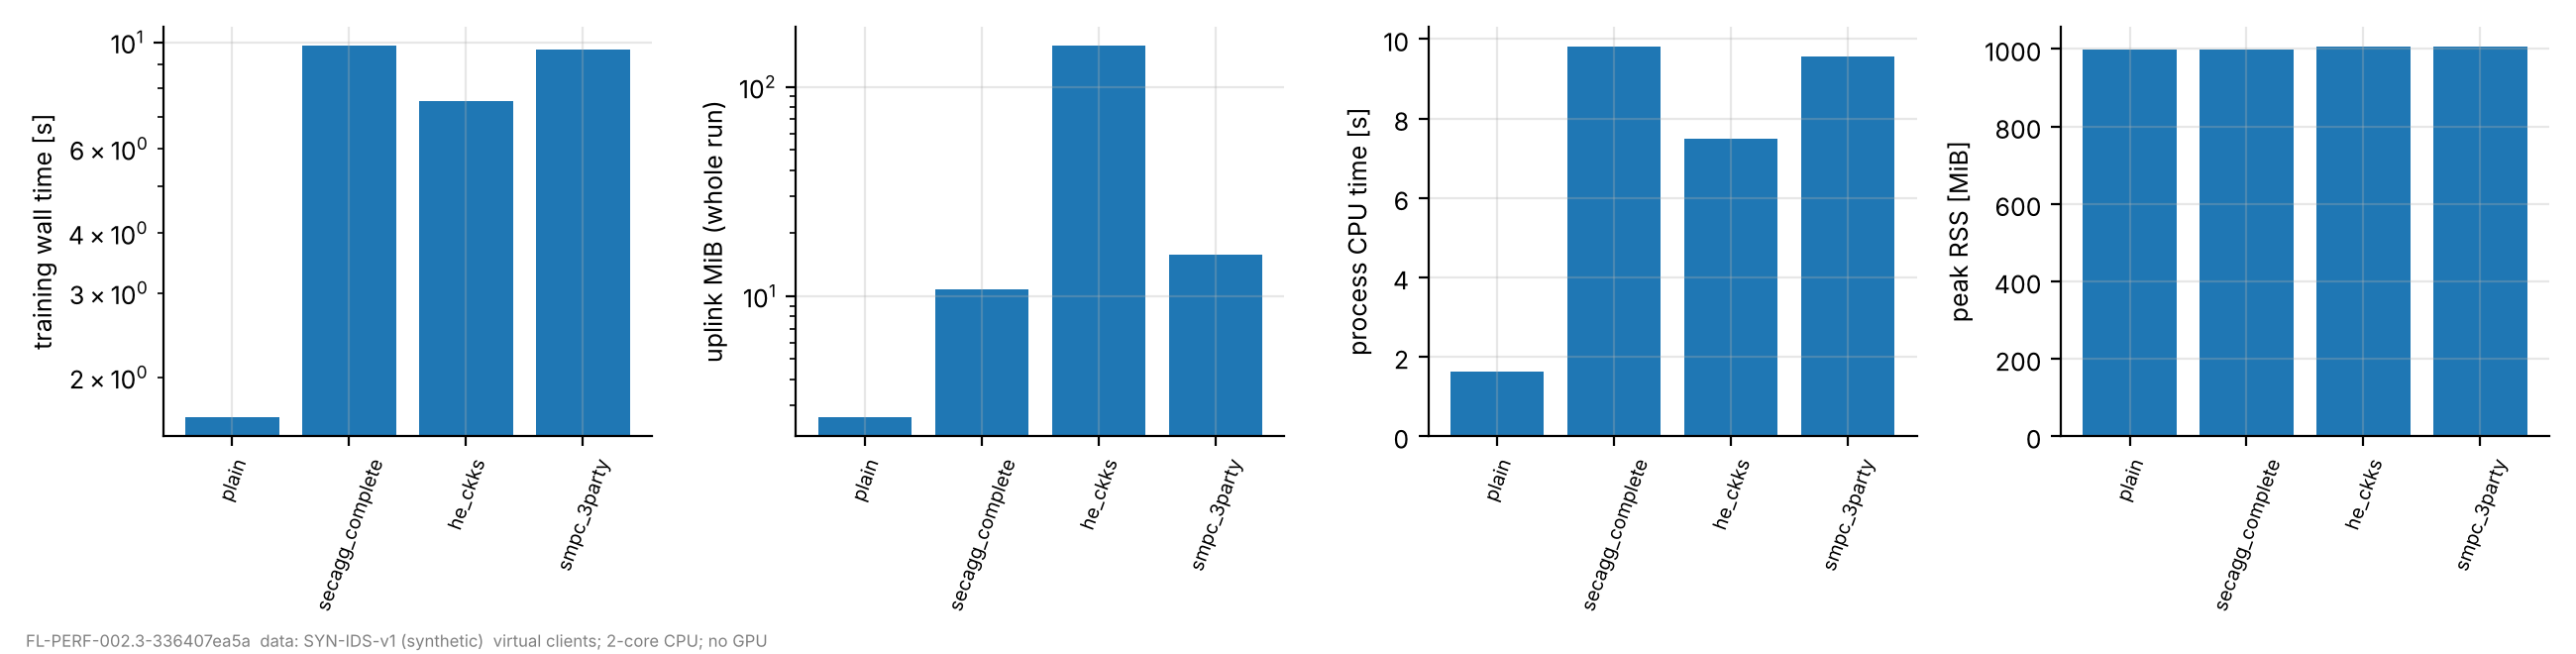

In [10]:
show_fig('task_2_3_benchmark_50.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Overheads grow with client count for pairwise-masking designs.

In [11]:
print('see stored tables above; KPI verdicts are in task_2_5_kpi_check.csv (task 2.5)')

see stored tables above; KPI verdicts are in task_2_5_kpi_check.csv (task 2.5)


## 16. Limitations
- Virtual clients: time does not reflect parallel hospitals or network latency.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md for the KPI verdicts; they are reported as measured, including NOT MET.

**Jira acceptance:** see `docs/fl_perf_002/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`kairouz2021`, `li2020challenges`, `bonawitz2017`, `cheon2017` — details in `docs/fl_perf_002/references.md`.